# 10. FLRW cosmology
For $ds^2=-dt^2+a^2[dr^2/(1-kr^2)+r^2d\Omega^2]$ the engine gives $G^t{}_t=-3(\dot a^2+k)/a^2$ and $G^r{}_r=-(2a\ddot a+\dot a^2+k)/a^2$. With a perfect fluid and $\Lambda$ these are the Friedmann equations. The continuity equation is *not* imposed: it follows from the contracted Bianchi identity.

In [1]:
import sympy as sp
from gr_from_scratch.field_equations.vacuum_equations import compute_geometry, field_equation_residual
from gr_from_scratch.field_equations import stress_energy as se
from gr_from_scratch.spacetimes import flrw as fl
g = compute_geometry(fl.flrw())
a = fl.a(fl.t); ad = sp.diff(a, fl.t); add = sp.diff(a, fl.t, 2)
Gm = g.einstein.raise_index(0).c
print('G^t_t =', sp.simplify(Gm[0,0])); print('G^r_r =', sp.simplify(Gm[1,1]))
rho = 3*(ad**2 + fl.k)/(8*sp.pi*a**2); p = -(2*a*add + ad**2 + fl.k)/(8*sp.pi*a**2)
print('Einstein eq with this fluid holds:', field_equation_residual(g, se.perfect_fluid(g.metric, rho, p, [1,0,0,0])).is_zero())
print('continuity residual (not imposed):', sp.simplify(sp.diff(rho, fl.t) + 3*ad/a*(rho+p)))

G^t_t = 3*(-k - Derivative(a(t), t)**2)/a(t)**2
G^r_r = (-k - 2*a(t)*Derivative(a(t), (t, 2)) - Derivative(a(t), t)**2)/a(t)**2


Einstein eq with this fluid holds: True
continuity residual (not imposed): 0


**Numerics versus analytic solutions** ($H_0=1$). Initial data are taken from the analytic solution, so the comparison tests the integrator and the ODE, while the derivation of the ODE from $G=8\pi T$ is the symbolic check above.

matter     max rel. error 3.4e-11   max constraint 3.4e-10
radiation  max rel. error 3.3e-10   max constraint 9.1e-09
de Sitter  max rel. error 3.1e-11   max constraint 5.4e-11
LCDM       max rel. error 2.5e-11   max constraint 1.1e-09


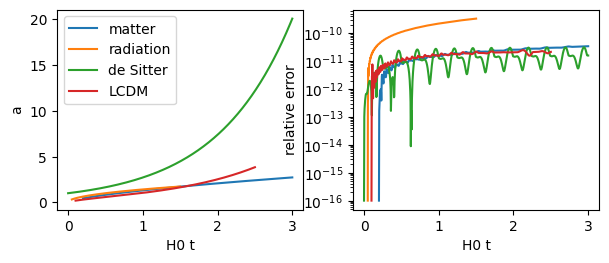

In [2]:
import numpy as np, matplotlib.pyplot as plt
from gr_from_scratch.numerical import friedmann as fr
def run(c, afn, t0, t1):
    h=1e-6; a0=afn(t0); ad0=(afn(t0+h)-afn(t0-h))/(2*h)
    t,a,_,con = fr.integrate(c, a0, ad0, t1-t0); return t+t0, a, afn(t+t0), con
cases = {'matter': run(fr.Cosmology(om_m=1), fr.a_matter_flat, .2, 3), 'radiation': run(fr.Cosmology(om_r=1), fr.a_radiation_flat, .05, 1.5),
         'de Sitter': run(fr.Cosmology(om_l=1), fr.a_de_sitter, 0, 3), 'LCDM': run(fr.Cosmology(om_m=.3, om_l=.7), lambda t: fr.a_lcdm_flat(t,.3), .1, 2.5)}
fig, ax = plt.subplots(1, 2, figsize=(7, 2.6))
for n, (t, a, ref, con) in cases.items():
    ax[0].plot(t, a, label=n); ax[1].semilogy(t, np.abs(a-ref)/ref+1e-16)
    print(f'{n:10s} max rel. error {np.max(np.abs(a-ref)/ref):.1e}   max constraint {np.abs(con).max():.1e}')
ax[0].legend(); ax[0].set(xlabel='H0 t', ylabel='a'); ax[1].set(xlabel='H0 t', ylabel='relative error'); plt.show()